# 04 · Validación de la simulación

**Fase CRISP-DM:** 2. Entendimiento de los datos

**Pregunta que responde:** *¿cómo sabemos que los datos sintéticos se parecen a la realidad y que tienen algo que aprender?*

1. **Hechos estilizados:** patrones que muestra cualquier dato real de restaurantes, comparados contra **bandas plausibles declaradas antes de ver los resultados** (`config/validation.yaml`).
2. **Ajuste a lo configurado:** lo simulado contra lo pedido (variación total, Kolmogorov-Smirnov, Wasserstein).
3. **Réplicas Monte Carlo:** ¿cuánto varían los resultados con otra semilla?
4. **Calibración por hipercubo latino:** ¿el problema no es ni aleatorio ni trivial?

> **Advertencia (supuesto general):** los datos sintéticos validan el pipeline y la arquitectura, no el rendimiento real del modelo. Ese se mide con datos de Puzzle y con la prueba A/B.

## Configuración y carga de la corrida

In [1]:
import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats

from puzzle_recsys.catalog.library import load_library
from puzzle_recsys.config import load_paths, load_simulation, load_yaml
from puzzle_recsys.eda.plots import plot_compare, plot_lorenz
from puzzle_recsys.repository.parquet_repo import ParquetRepository, run_id_for
from puzzle_recsys.simulation.assemble import tastes_from_frame
from puzzle_recsys.simulation.calibration import latin_hypercube, run_scenario, with_params
from puzzle_recsys.simulation.distributions import make_rng
from puzzle_recsys.simulation.engine import build_world_index
from puzzle_recsys.validation.synthetic_checks import in_band, stylized_facts, total_variation

paths, sim, val = load_paths(), load_simulation(), load_yaml("validation")
repo = ParquetRepository(paths.synthetic / run_id_for(sim.run_name, sim.seed))
gt = repo.ground_truth
sessions = repo.read_table("dining_sessions")
guests = repo.read_table("guests").merge(gt.read_table("guest_tastes"), on="guest_id")
# El ruido quitó el comensal a algunas líneas (pedidos del mesero): para medir el
# comportamiento se usa el comensal VERDADERO (verdad oculta).
lines = (
    repo.read_table("order_items")
    .drop(columns="guest_id")
    .merge(
        gt.read_table("order_item_guests").rename(columns={"guest_id_true": "guest_id"}),
        on="order_item_id",
    )
)
restaurants = repo.read_table("restaurants")
canonical_of = gt.read_table("menu_items").set_index("menu_item_id")["canonical_true"]
tastes_df = gt.read_table("diner_tastes")
cuisines = sorted(restaurants["cuisine_pred"].unique())
favorite = dict(
    zip(
        tastes_df["diner_id"],
        np.array(cuisines)[np.vstack(tastes_df["cuisine_affinity"]).argmax(axis=1)],
        strict=True,
    )
)
print(f"{len(sessions):,} visitas · {len(lines):,} líneas · {len(tastes_df):,} comensales")

512,907 visitas · 3,396,760 líneas · 20,000 comensales


## 1. Hechos estilizados (corrida completa)

| Hecho | Por qué importa |
|---|---|
| **20 % de los platillos concentra 60–85 % de los pedidos** | Regla 80/20 de la ingeniería de menús |
| **Visitas a la cocina favorita: 30–65 %** | La gente prefiere lo suyo, pero explora |
| **Recompra del mismo platillo canónico: 20–60 %** | Es la señal que el recomendador aprende; fuera de la banda, el problema sería aleatorio o trivial |
| **Mesas que comparten algo: 10–40 %** | Da sentido a la lista "para la mesa" |
| **Cola pesada de frecuencia: p90/p50 entre 1.8 y 5** | Pocos comensales muy frecuentes, como en cualquier negocio |

> **Corrección de diseño (transparencia):** la primera versión de este notebook no especificaba la **unidad** ni el **horizonte** de las métricas. Resultado: la concentración (medida sobre ~36,000 platillos servidos) dependía del tamaño de la muestra y la recompra dependía del tiempo observado, así que la corrida completa y los escenarios reducidos no eran comparables. Ahora la concentración se mide sobre **platillos canónicos** y todas las métricas en la **misma ventana de 3 meses**. Las bandas no cambiaron: se definió bien qué miden.

In [2]:
window_end = pd.Timestamp(sim.calendar["start_date"], tz=sim.calendar["timezone"]) + pd.DateOffset(
    months=val["calibration"]["months"]
)
facts = stylized_facts(
    sessions,
    guests,
    lines,
    canonical_of=canonical_of,
    restaurant_cuisine=restaurants.set_index("restaurant_id")["cuisine_pred"],
    favorite_cuisine=favorite,
    window_end=window_end,
)
year = stylized_facts(
    sessions,
    guests,
    lines,
    canonical_of=canonical_of,
    restaurant_cuisine=restaurants.set_index("restaurant_id")["cuisine_pred"],
    favorite_cuisine=favorite,
)
year_repeat = year["repeat_rate_canonical"]
print(f"Recompra con 12 meses de historial (informativo, fuera de la banda): {year_repeat:.3f}")
bands = val["stylized_facts"]
pd.DataFrame(
    {
        "simulado": facts,
        "banda": {k: f"{bands[k][0]:.2f} a {bands[k][1]:.2f}" for k in facts},
        "¿dentro?": {k: "✔" if in_band(v, bands[k]) else "✘" for k, v in facts.items()},
    }
).round(3)

Recompra con 12 meses de historial (informativo, fuera de la banda): 0.605


,simulado,banda,¿dentro?
top20_share_dishes,0.810,0.60 a 0.85,✔
favorite_cuisine_share,0.475,0.30 a 0.65,✔
repeat_rate_canonical,0.325,0.20 a 0.60,✔
shared_table_rate,0.225,0.10 a 0.40,✔
visits_p90_over_p50,2.800,1.80 a 5.00,✔


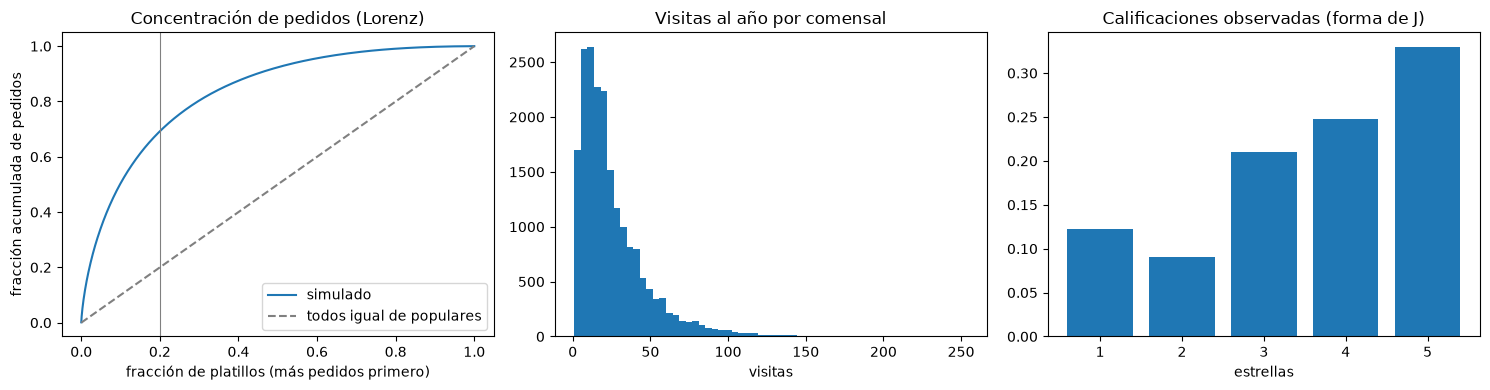

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
plot_lorenz(
    lines["menu_item_id"].value_counts(), title="Concentración de pedidos (Lorenz)", ax=axes[0]
)
visits = guests[guests["is_host"]].groupby("taste_ref").size()
axes[1].hist(visits, bins=60)
axes[1].set_title("Visitas al año por comensal")
axes[1].set_xlabel("visitas")
stars = repo.read_table("dish_ratings")["stars"].value_counts(normalize=True).sort_index()
axes[2].bar(stars.index, stars.to_numpy())
axes[2].set_title("Calificaciones observadas (forma de J)")
axes[2].set_xlabel("estrellas")
fig.tight_layout()
fig.savefig(paths.figures / "04_hechos_estilizados.png", dpi=150)

## 2. Ajuste a lo configurado

Para distribuciones **categóricas** (día, hora, tamaño de mesa) se usa la **variación total**: la mitad de la suma de diferencias absolutas, entre 0 (idénticas) y 1 (sin nada en común). Umbral: 0.03.

El **tamaño de mesa** se compara contra la mezcla esperada: el contexto lo deforma a propósito (más mesas grandes el fin de semana y menos en el desayuno, supuesto S16).

,variación total,¿< 0.03?
día de la semana,0.0026,✔
hora de llegada,0.0023,✔
tamaño de mesa,0.0014,✔


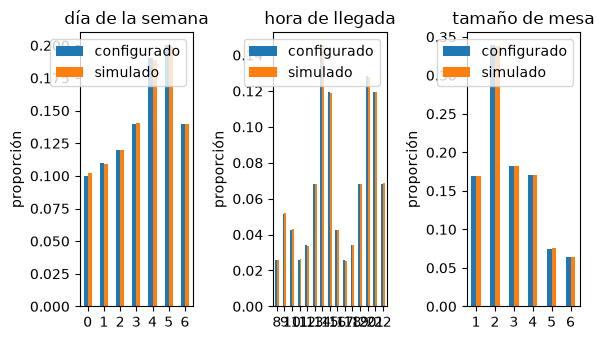

In [4]:
from puzzle_recsys.simulation.context import expected_pax_distribution

local = sessions["opened_at"].dt.tz_convert(sim.calendar["timezone"])
w = np.asarray(sim.visits["weekday_weights"], dtype=float)
hours = {int(h): p for h, p in sim.visits["hourly_profile"].items()}
pax_values = np.array([int(k) for k in sim.visits["pax_probs"]])
# El contexto (fin de semana, desayuno) deforma pax_probs a propósito (S16):
# lo esperado es la mezcla sobre días y horas, no la tabla base.
pax_expected = expected_pax_distribution(
    pax_values, np.array(list(sim.visits["pax_probs"].values()), dtype=float),
    sim.visits["weekday_weights"], sim.visits["hourly_profile"], sim.visits["party_size_context"],
)
comparisons = {
    "día de la semana": (
        pd.Series(w / w.sum(), index=range(7)),
        local.dt.day_of_week.value_counts(normalize=True),
    ),
    "hora de llegada": (
        pd.Series(hours) / sum(hours.values()),
        local.dt.hour.value_counts(normalize=True),
    ),
    "tamaño de mesa": (
        pd.Series(pax_expected, index=pax_values),
        sessions.loc[sessions["pax"] <= 6, "pax"].value_counts(normalize=True),
    ),
}
limit = val["fit_to_config"]["max_total_variation"]
rows = {}
fig, axes = plt.subplots(1, 3, figsize=(16, 3.5))
for ax, (name, (expected, observed)) in zip(axes, comparisons.items(), strict=True):
    observed = observed.reindex(expected.index, fill_value=0)
    rows[name] = {"variación total": total_variation(expected, observed)}
    plot_compare(expected, observed, title=name, ax=ax)
fig.tight_layout()
pd.DataFrame(rows).T.assign(
    **{"¿< 0.03?": lambda d: np.where(d["variación total"] < limit, "✔", "✘")}
).round(4)

Para variables **continuas**, el presupuesto declarado (ENIGH) contra el gasto real por visita. **No deben ser iguales:** el presupuesto es lo que la persona *podría* gastar; el gasto, lo que eligió **dentro de menús reales de precio acotado**. Kolmogorov-Smirnov y Wasserstein (en escala logarítmica) cuantifican la brecha entre ambas distribuciones: si difieren en **nivel** (el gasto es una fracción del presupuesto), en **dispersión**, o en ambas.

In [5]:
homes = gt.read_table("diner_homes")
host = guests[guests["is_host"]][["guest_id", "taste_ref"]]
spend = (
    lines.merge(host, on="guest_id")
    .query("~is_shared")
    .groupby(["session_id", "taste_ref"])["unit_price_cents"]
    .sum()
    / 100
)
log_budget = np.log(homes["budget"])
log_spend = np.log(spend.to_numpy())
ks = stats.ks_2samp(log_budget, log_spend)
pd.Series(
    {
        "KS estadístico": ks.statistic,
        "Wasserstein (log)": stats.wasserstein_distance(log_budget, log_spend),
        "desv. estándar log presupuesto": log_budget.std(),
        "desv. estándar log gasto": log_spend.std(),
    }
).round(3).to_frame("valor").T

,KS estadístico,Wasserstein (log),desv. estándar log presupuesto,desv. estándar log gasto
valor,0.366,0.48,0.528,0.546


## 3. Réplicas Monte Carlo

Se repite un escenario reducido (los primeros 1,000 comensales, 3 meses) con **semillas distintas** sobre la misma población. Si los hechos estilizados cambiaran mucho de una semilla a otra, las conclusiones dependerían del azar.

La población se reconstruye **desde la verdad oculta** guardada (no se vuelve a generar), así que es exactamente la del notebook 03.

In [6]:
library = load_library(paths.external / "canonical_dishes.yaml")
names = (
    "restaurants",
    "canonical_dishes",
    "menu_items",
    "menu_item_attributes",
    "menu_item_price_history",
    "menu_item_availability_events",
)
tables = {n: repo.read_table(n) for n in names}
tables["ground_truth_menu_items"] = gt.read_table("menu_items")
habit_beta = sim.population["taste"]["course_habit_beta"]
habits = {"MAIN": sim.visits["main_course_rate"]} | {
    c: b["a"] / (b["a"] + b["b"]) for c, b in habit_beta.items()
}
index, _ = build_world_index(
    tables,
    library,
    cuisines,
    sim.choice,
    sim.calendar["timezone"],
    make_rng(sim.seed, "world_index"),
    course_habit_means=habits,
)
proteins = ["BEEF", "PORK", "CHICKEN", "FISH", "SEAFOOD", "PLANT", "EGG", "CHEESE", "MIXED"]
name_kwargs = dict(
    cuisines=cuisines,
    proteins=proteins,
    ingredients=list(library.ingredients),
    allergens=list(library.allergens),
)
anon_df = gt.read_table("anonymous_tastes")
world = {
    "index": index,
    "tastes": tastes_from_frame(tastes_df, **name_kwargs),
    "homes": homes[["lat", "lng"]],
    "budgets": homes["budget"].to_numpy(),
    "frequency": homes["frequency"].to_numpy(),
    # Presupuesto de los acompañantes anónimos: el mismo que se simuló en el nb 03.
    "anonymous": (
        tastes_from_frame(anon_df, **name_kwargs),
        anon_df["budget"].to_numpy(),
    ),
}
engine_cfg = {
    k: getattr(sim, k) for k in ("visits", "choice", "sharing", "population", "ratings", "noise")
}
cal = val["calibration"]


def facts_of(out):
    return stylized_facts(
        out["dining_sessions"],
        out["guests"],
        out["order_items"],
        canonical_of=dict(
            zip(
                index.item_ids,
                tables["ground_truth_menu_items"]
                .set_index("menu_item_id")
                .loc[index.item_ids, "canonical_true"],
                strict=True,
            )
        ),
        restaurant_cuisine=restaurants.set_index("restaurant_id")["cuisine_pred"],
        favorite_cuisine=favorite,
        window_end=window_end,
    )


replicas = pd.DataFrame(
    [
        facts_of(
            run_scenario(
                world,
                engine_cfg,
                sim.calendar,
                n_diners=cal["n_diners"],
                months=cal["months"],
                seed=s,
            )
        )
        for s in range(val["monte_carlo"]["n_replicas"])
    ]
)
replicas.agg(["mean", "std", "min", "max"]).T.round(3)

,mean,std,min,max
top20_share_dishes,0.805,0.004,0.800,0.811
favorite_cuisine_share,0.456,0.006,0.446,0.464
repeat_rate_canonical,0.309,0.003,0.305,0.313
shared_table_rate,0.224,0.002,0.221,0.228
visits_p90_over_p50,2.720,0.110,2.600,2.800


## 4. Calibración por hipercubo latino

Tres parámetros que no se pueden estimar sin datos reales:

- `choice.gumbel_scale`: tamaño del ruido (más ruido = elecciones más aleatorias).
- `choice.affinity_weight`: cuánto pesa el gusto por la cocina.
- `price_sensitivity_scale`: multiplica la sensibilidad al precio (λ) de cada comensal.

El **hipercubo latino** divide cada rango en 12 franjas y usa cada franja exactamente una vez, así que 12 corridas cubren todo el espacio. Para cada corrida se miden los hechos estilizados y se marca si **todos** caen en sus bandas.

In [7]:
design = latin_hypercube(cal["bounds"], n=cal["n_runs"], rng=make_rng(sim.seed, "lhs"))
runs = []
for k, row in design.iterrows():
    params = row.to_dict()
    scale = params.pop("price_sensitivity_scale")
    out = run_scenario(
        world,
        with_params(engine_cfg, params),
        sim.calendar,
        n_diners=cal["n_diners"],
        months=cal["months"],
        seed=100 + k,
        price_sensitivity_scale=scale,
    )
    runs.append(facts_of(out))
calibration = pd.concat([design, pd.DataFrame(runs)], axis=1)
calibration["todas en banda"] = calibration[list(bands)].apply(
    lambda r: all(in_band(r[c], bands[c]) for c in bands), axis=1
)
calibration.round(3)

,choice.gumbel_scale,choice.affinity_weight,price_sensitivity_scale,top20_share_dishes,favorite_cuisine_share,repeat_rate_canonical,shared_table_rate,visits_p90_over_p50,todas en banda
0,1.091,1.962,0.635,0.807,0.574,0.350,0.217,3.0,True
1,0.996,0.798,0.825,0.809,0.417,0.302,0.222,2.8,True
2,1.901,1.765,0.525,0.787,0.460,0.279,0.218,2.6,True
3,0.573,1.399,1.407,0.814,0.594,0.410,0.226,2.6,True
4,0.873,1.038,0.908,0.805,0.489,0.345,0.215,2.8,True
5,1.225,0.606,1.977,0.771,0.334,0.268,0.221,2.8,True
6,1.723,1.697,1.782,0.787,0.469,0.281,0.223,2.8,True
7,1.826,0.710,1.558,0.765,0.322,0.242,0.216,2.8,True
8,1.596,1.213,1.017,0.781,0.420,0.270,0.222,2.6,True
9,0.669,1.300,1.698,0.816,0.551,0.385,0.222,2.8,True


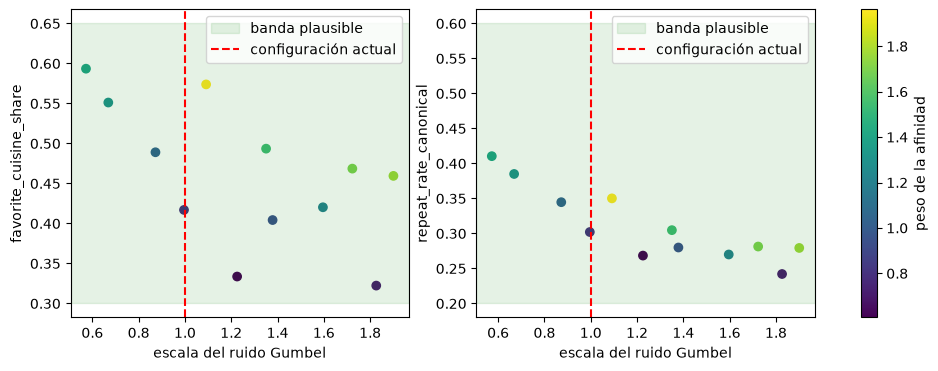

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, metric in zip(axes, ["favorite_cuisine_share", "repeat_rate_canonical"], strict=True):
    sc = ax.scatter(
        calibration["choice.gumbel_scale"],
        calibration[metric],
        c=calibration["choice.affinity_weight"],
        cmap="viridis",
    )
    ax.axhspan(*bands[metric], color="green", alpha=0.1, label="banda plausible")
    ax.axvline(
        sim.choice["gumbel_scale"], color="red", linestyle="--", label="configuración actual"
    )
    ax.set_xlabel("escala del ruido Gumbel")
    ax.set_ylabel(metric)
    ax.legend()
fig.colorbar(sc, ax=axes, label="peso de la afinidad")
fig.savefig(paths.figures / "04_calibracion.png", dpi=150, bbox_inches="tight")

## Conclusiones

- **Los 5 hechos estilizados caen en sus bandas** (declaradas antes de ver resultados): el 20 % de los platillos concentra el **81 %** de los pedidos (regla 80/20), el **47.5 %** de las visitas va a la cocina favorita, el **32 %** de los pedidos recompra un platillo ya pedido (ventana de 3 meses), el **22 %** de las mesas comparte algo y la frecuencia tiene cola pesada (p90/p50 = **2.8**).
- **La simulación hace lo que se le pidió:** día, hora y tamaño de mesa reproducen lo configurado con variación total de **0.001 a 0.003** (umbral 0.03). El tamaño de mesa se compara contra la mezcla esperada sobre días y horas, porque el contexto lo deforma a propósito (S16).
- **Presupuesto y gasto:** tienen casi la misma dispersión (0.53 contra 0.55 en log), pero el gasto real está **por debajo** del presupuesto (Wasserstein 0.48 en log): la gente gasta una fracción de lo que podría, porque los menús acotan los precios.
- **Monte Carlo:** entre semillas, las proporciones varían con desviación estándar de **0.006 o menos**; el p90/p50 oscila entre 2.6 y 2.8 porque es un cociente de conteos enteros (salta de a pasos). Las conclusiones no dependen del azar. Y los escenarios reducidos reproducen la corrida completa (concentración 0.80 contra 0.81; recompra 0.31 contra 0.32), lo que valida usarlos para calibrar.
- **Calibración:** las **12 corridas** del hipercubo latino caen en las bandas. Lectura doble: (1) los hechos estilizados son **robustos** a la incertidumbre de los parámetros, y la configuración actual está dentro de la región plausible; (2) estos hechos **no alcanzan para identificar** los parámetros exactos (la visita a la cocina favorita va de 0.32 a 0.59 según el peso de la afinidad). Fijar valores precisos requiere datos reales de Puzzle.
- **Tres errores de diseño encontrados y corregidos** en esta validación (cada uno con su test de regresión): la concentración dependía del tamaño de la muestra, la recompra dependía del horizonte, y la recompra contaba a los acompañantes anónimos (perfiles reutilizados entre mesas) como si fueran la misma persona.
- **Pasa al notebook 05:** calidad de datos (el ruido sembrado a propósito debe aparecer en el diagnóstico).